In [125]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [105]:
df=pd.read_csv("data/HouseData.csv")

In [106]:
model=LinearRegression()

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   area_sqft         2000 non-null   int64 
 1   bhk               2000 non-null   int64 
 2   city              2000 non-null   object
 3   city_price_level  2000 non-null   object
 4   price_inr         2000 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 78.2+ KB


In [108]:
df.head()

,area_sqft,bhk,city,city_price_level,price_inr
0,959,2,Bhopal,Lower,3850000
1,2838,4,Mumbai,Very High,54520000
2,633,2,Indore,Medium,3520000
3,2720,2,Bengaluru,High,27020000
4,1999,3,Indore,Medium,11560000


In [109]:
df.describe()

,area_sqft,bhk,price_inr
count,2000.000000,2000.000000,2.000000e+03
mean,1686.404500,2.777000,1.682276e+07
std,718.555435,1.095843,1.233029e+07
min,416.000000,1.000000,1.740000e+06
25%,1053.750000,2.000000,7.917500e+06
50%,1597.500000,3.000000,1.297000e+07
75%,2338.000000,4.000000,2.283000e+07
max,3000.000000,5.000000,6.855000e+07


In [110]:
df["city"].unique()

array(['Bhopal', 'Mumbai', 'Indore', 'Bengaluru', 'Delhi'], dtype=object)

In [111]:
df["city"].value_counts()

city
Bhopal       400
Mumbai       400
Indore       400
Bengaluru    400
Delhi        400
Name: count, dtype: int64

In [112]:
X = df.drop(["price_inr", "city_price_level"], axis=1)
y=df["price_inr"]

In [113]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   area_sqft  2000 non-null   int64 
 1   bhk        2000 non-null   int64 
 2   city       2000 non-null   object
dtypes: int64(2), object(1)
memory usage: 47.0+ KB


In [114]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 2000 entries, 0 to 1999
Series name: price_inr
Non-Null Count  Dtype
--------------  -----
2000 non-null   int64
dtypes: int64(1)
memory usage: 15.8 KB


In [115]:
le=LabelEncoder()

In [116]:
X["city"]=le.fit_transform(X["city"])

In [117]:
X.head()

,area_sqft,bhk,city
0,959,2,1
1,2838,4,4
2,633,2,3
3,2720,2,0
4,1999,3,3


In [118]:
X["city"].unique()

array([1, 4, 3, 0, 2])

In [119]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [120]:
model=LinearRegression()

In [121]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [122]:
model.score(x_test,y_test)

0.49109171498721305

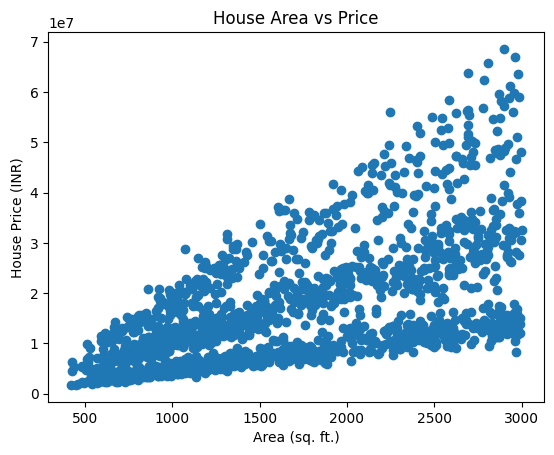

In [126]:


plt.scatter(x_train["area_sqft"], y_train)

plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price (INR)")
plt.title("House Area vs Price")

plt.show()


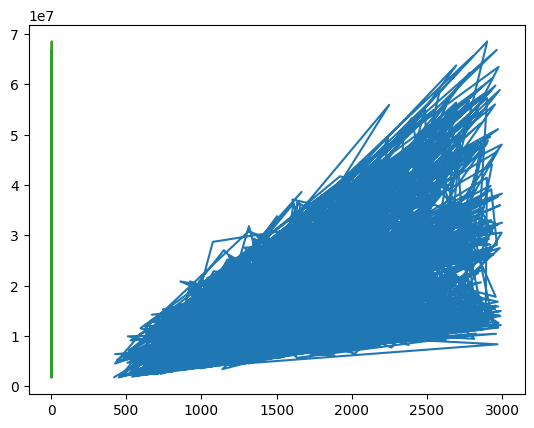

In [127]:
plt.plot(x_train,y_train)